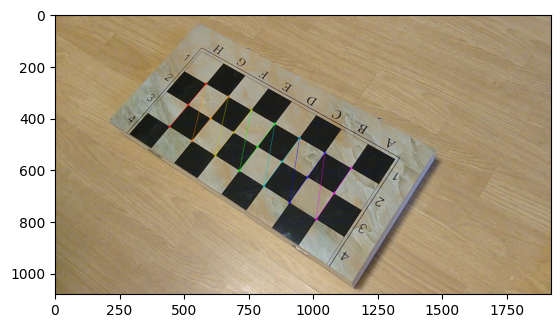

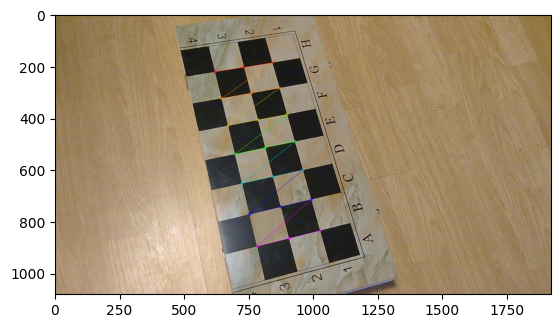

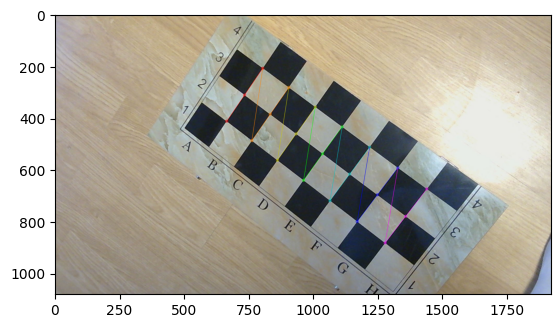

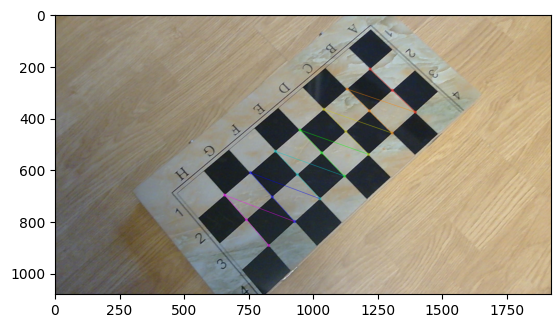

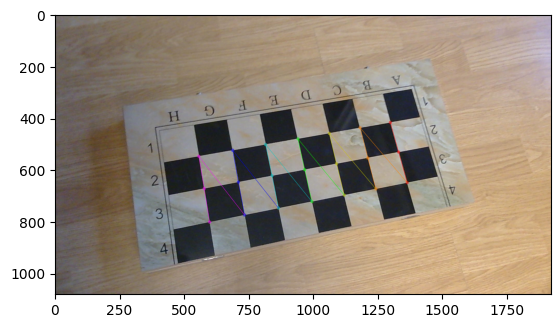

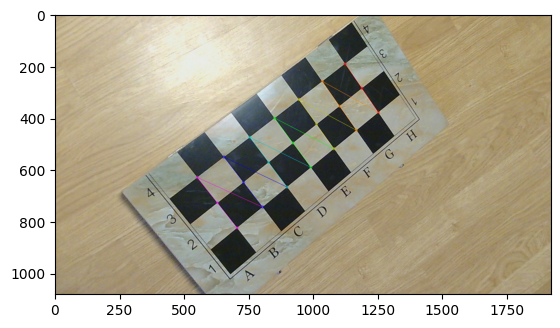

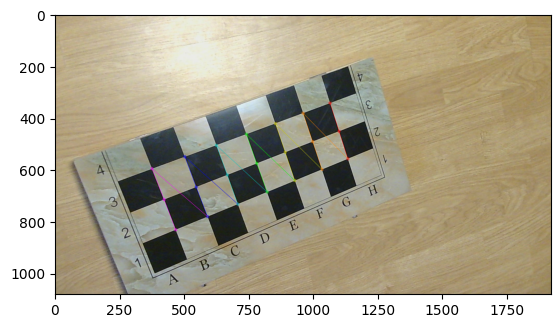

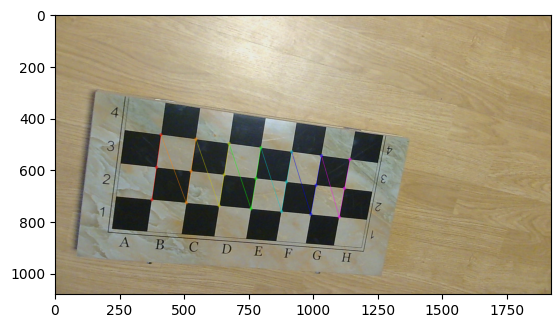

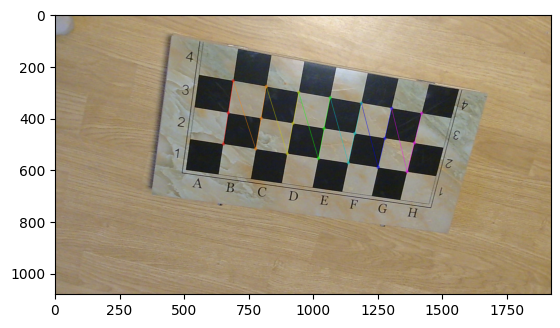

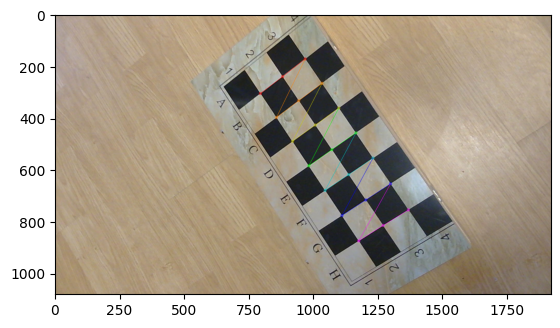

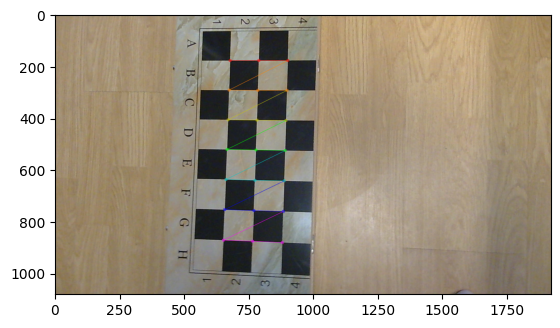

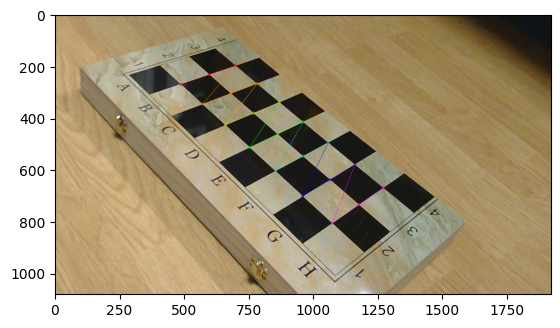

Camera matrix : 
 [[1.98329948e+03 0.00000000e+00 1.02093936e+03]
 [0.00000000e+00 1.97503382e+03 4.53321600e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion coefficients : 
 [[ 0.04614473  0.3393293  -0.00468062  0.0048498  -0.81189409]]


In [2]:
import cv2
import numpy as np
import glob
import matplotlib.pyplot as plt

# Termination criteria for the corner sub-pixel accuracy
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

# Prepare grid dimensions and square size in the real world (e.g., in meters)
chessboard_size = (3, 7)  # Number of internal corners per a chessboard row and column
square_size = 0.049  # Size of a square in meters

# Prepare object points (0,0,0), (1,0,0), (2,0,0), ..., (8,5,0)
objp = np.zeros((chessboard_size[0] * chessboard_size[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:chessboard_size[0], 0:chessboard_size[1]].T.reshape(-1, 2)
objp *= square_size

# Arrays to store object points and image points from all images
objpoints = []  # 3D points in real world space
imgpoints = []  # 2D points in image plane

# Get list of calibration images
images = glob.glob('logitech_brio_100/*.jpg')  # Update the path to your images

for fname in images:
    img = cv2.imread(fname)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Find the chessboard corners
    ret, corners = cv2.findChessboardCorners(gray, chessboard_size, None)

    # If found, add object points, image points
    if ret:
        objpoints.append(objp)

        corners2 = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)
        imgpoints.append(corners2)

        # Draw and display the corners
        cv2.drawChessboardCorners(img, chessboard_size, corners2, ret)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.show()

# Perform camera calibration
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, gray.shape[::-1], None, None)

# Print the camera matrix and distortion coefficients
print("Camera matrix : \n", mtx)
print("Distortion coefficients : \n", dist)

# Save the calibration result for later use
np.savez('logitech_brio_100.npz', mtx=mtx, dist=dist, rvecs=rvecs, tvecs=tvecs)